<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/26_RNN__GRU_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### GRU Implementation from Scratch

We now translate the GRU equations into TensorFlow code.

At each time step, the GRU performs four main operations.

**1. Update gate**

$$
Z_t = \sigma \left( X_t W_{xz} + H_{t-1} W_{hz} + b_z \right)
$$

The update gate controls how much of the previous hidden state is retained.

---

**2. Reset gate**

$$
R_t = \sigma \left( X_t W_{xr} + H_{t-1} W_{hr} + b_r \right)
$$

The reset gate controls how much of the previous hidden state is used when creating the candidate hidden state.

---

**3. Candidate hidden state**

$$
\tilde{H}_t =
\tanh \left(
X_t W_{xh}
+
\left( R_t \odot H_{t-1} \right) W_{hh}
+
b_h
\right)
$$

The reset gate is applied elementwise to the previous hidden state before the candidate is created.

---

**4. Final hidden state**

$$
H_t =
Z_t \odot H_{t-1}
+
\left( 1 - Z_t \right) \odot \tilde{H}_t
$$

The update gate determines the balance between the old hidden state and the new candidate hidden state.

> **Key idea:**  
> Reset gate → helps create the candidate.  
> Update gate → decides how much old vs. new information becomes the final hidden state.

In [ ]:
!pip install --q D2l --no-deps

In [ ]:
import tensorflow as tf
from d2l import tensorflow as d2l


In [ ]:
class GRUScratch(d2l.Module):
    def __init__(self, num_inputs, num_hiddens, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()

        # -----------------------------------------------------
        # Create trainable weights
        # -----------------------------------------------------
        # add_weight() lets current Keras correctly track
        # these parameters during training.
        def init_weight(shape, name):
            return self.add_weight(
                name=name,
                shape=shape,
                initializer=tf.keras.initializers.RandomNormal(
                    mean=0.0,
                    stddev=sigma
                ),
                trainable=True
            )

        # Each GRU component needs:
        # 1. weights from current input X_t
        # 2. weights from previous hidden state H_{t-1}
        # 3. bias
        def triple(name):
            W_x = init_weight(
                (num_inputs, num_hiddens),
                f"W_x{name}"
            )

            W_h = init_weight(
                (num_hiddens, num_hiddens),
                f"W_h{name}"
            )

            b = self.add_weight(
                name=f"b_{name}",
                shape=(num_hiddens,),
                initializer="zeros",
                trainable=True
            )

            return W_x, W_h, b

        # Update gate parameters
        self.W_xz, self.W_hz, self.b_z = triple("z")

        # Reset gate parameters
        self.W_xr, self.W_hr, self.b_r = triple("r")

        # Candidate hidden-state parameters
        self.W_xh, self.W_hh, self.b_h = triple("h")


    def forward(self, inputs, H=None):

        # -----------------------------------------------------
        # Initialize hidden state
        # -----------------------------------------------------
        # Shape: (batch_size, num_hiddens)
        if H is None:
            H = tf.zeros(
                (inputs.shape[1], self.num_hiddens)
            )

        outputs = []

        # Process one time step at a time
        for X in inputs:

            # -------------------------------------------------
            # 1. UPDATE GATE
            # How much of the old hidden state should we keep?
            #
            # Z_t = sigmoid(X_t W_xz + H_{t-1} W_hz + b_z)
            # -------------------------------------------------
            Z = tf.sigmoid(
                tf.matmul(X, self.W_xz) +
                tf.matmul(H, self.W_hz) +
                self.b_z
            )

            # -------------------------------------------------
            # 2. RESET GATE
            # How much of the old hidden state should be used
            # when creating the candidate hidden state?
            #
            # R_t = sigmoid(X_t W_xr + H_{t-1} W_hr + b_r)
            # -------------------------------------------------
            R = tf.sigmoid(
                tf.matmul(X, self.W_xr) +
                tf.matmul(H, self.W_hr) +
                self.b_r
            )

            # -------------------------------------------------
            # 3. CANDIDATE HIDDEN STATE
            #
            # R * H is ELEMENTWISE multiplication.
            #
            # H~_t = tanh(
            #     X_t W_xh +
            #     (R_t * H_{t-1}) W_hh +
            #     b_h
            # )
            # -------------------------------------------------
            H_tilde = tf.tanh(
                tf.matmul(X, self.W_xh) +
                tf.matmul(R * H, self.W_hh) +
                self.b_h
            )

            # -------------------------------------------------
            # 4. FINAL HIDDEN STATE
            #
            # Keep some old information and combine it
            # with some candidate information.
            #
            # H_t = Z_t * H_{t-1}
            #       + (1 - Z_t) * H~_t
            # -------------------------------------------------
            H = Z * H + (1 - Z) * H_tilde

            # Save H_t for this time step
            outputs.append(H)

        # Return all hidden states and the final state
        return outputs, H

## Training the GRU Language Model

The internal recurrent architecture has changed from an LSTM to a GRU, but the **language-model training procedure remains the same**.

We continue using *The Time Machine* dataset for character-level next-character prediction.

The important training settings are:

- **Batch size = 1024:** number of sequences processed together
- **Sequence length = 32:** number of time steps in each sequence
- **Hidden units = 32:** size of the GRU hidden representation
- **Learning rate = 4**
- **Epochs = 50**
- **Gradient clipping = 1:** helps control exploding gradients

During training, the model learns the weights and biases of the:

- update gate
- reset gate
- candidate hidden state

We evaluate the language model using **perplexity (PPL)**.

Lower perplexity indicates that the model is becoming better at predicting the next character.

In [ ]:
# ---------------------------------------------------------
# Compatibility loss for current TensorFlow/Keras + D2L
# ---------------------------------------------------------

def d2l_rnn_loss(Y_hat, Y):

    # Flatten predictions:
    # (..., vocab_size)
    # ->
    # (all_predictions, vocab_size)
    Y_hat = tf.reshape(
        Y_hat,
        (-1, Y_hat.shape[-1])
    )

    # Flatten the true next-character IDs
    Y = tf.reshape(
        Y,
        (-1,)
    )

    # Cross-entropy for integer class labels
    loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    )

    return loss_fn(Y, Y_hat)

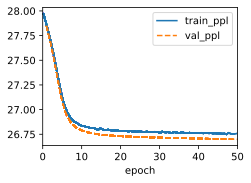

In [ ]:
# ---------------------------------------------------------
# 1. Load The Time Machine dataset
# ---------------------------------------------------------

data = d2l.TimeMachine(
    batch_size=1024,
    num_steps=32
)


# ---------------------------------------------------------
# 2. Create the GRU and language model
# ---------------------------------------------------------

with d2l.try_gpu():

    gru = GRUScratch(
        # Number of possible input characters
        num_inputs=len(data.vocab),

        # Size of the hidden state
        num_hiddens=32
    )

    model = d2l.RNNLMScratch(
        gru,

        # One output score for every possible character
        vocab_size=len(data.vocab),

        # Current Keras requires a float
        lr=4.0
    )


# ---------------------------------------------------------
# 3. Attach compatibility loss
# ---------------------------------------------------------

model.loss = d2l_rnn_loss


# ---------------------------------------------------------
# 4. Configure training
# ---------------------------------------------------------

trainer = d2l.Trainer(
    max_epochs=50,
    gradient_clip_val=1
)


# ---------------------------------------------------------
# 5. Train
# ---------------------------------------------------------

trainer.fit(model, data)

## GRU: Concise Implementation

In the from-scratch implementation, we explicitly created the GRU's:

- update gate
- reset gate
- candidate hidden state
- final hidden state

TensorFlow/Keras already provides an optimized GRU implementation through:

`tf.keras.layers.GRU`

Therefore, we no longer need to manually define the gate equations or their weight matrices.

Instead, we specify the main architecture, such as the number of hidden units, and Keras creates and manages the GRU parameters internally.



### From Scratch vs. Concise Implementation

**From scratch:**

We explicitly computed:

$$
Z_t = \sigma(X_tW_{xz} + H_{t-1}W_{hz} + b_z)
$$

$$
R_t = \sigma(X_tW_{xr} + H_{t-1}W_{hr} + b_r)
$$

$$
\tilde{H}_t =
\tanh\left(
X_tW_{xh} +
(R_t \odot H_{t-1})W_{hh} +
b_h
\right)
$$

$$
H_t =
Z_t \odot H_{t-1}
+
(1-Z_t)\odot\tilde{H}_t
$$

**Concise implementation:**

Keras performs these operations internally using:

`tf.keras.layers.GRU(...)`

The underlying GRU idea has not changed. We are simply using a high-level, optimized implementation instead of programming each operation ourselves.

In [ ]:
class GRU(d2l.RNN):
    def __init__(self, num_inputs, num_hiddens):
        d2l.Module.__init__(self)
        self.save_hyperparameters()

        # High-level Keras GRU layer
        self.rnn = tf.keras.layers.GRU(
            num_hiddens,
            return_sequences=True,
            return_state=True
        )

    def forward(self, inputs, H=None):

        # Run the Keras GRU
        outputs, H = self.rnn(
            inputs,
            initial_state=H
        )

        return outputs, H

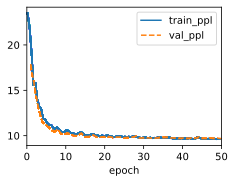

In [ ]:
gru = GRU(
    num_inputs=len(data.vocab),
    num_hiddens=32
)

with d2l.try_gpu():

    model = d2l.RNNLM(
        gru,
        vocab_size=len(data.vocab),
        lr=4.0
    )

    # Compatibility fix for current D2L/Keras
    model.loss = d2l_rnn_loss

    trainer.fit(model, data)

In [ ]:
model.predict('it has', 20, data.vocab)

## Summary

### Key Ideas

- A **GRU is a gated RNN** designed to capture longer-term dependencies more effectively than a simple RNN.

- A GRU uses **two gates**:
  - **Reset gate ($R_t$):** controls how much previous information is used when creating the candidate hidden state.
  - **Update gate ($Z_t$):** controls how much of the previous hidden state is retained versus replaced by new information.

- The GRU creates a **candidate hidden state** $\tilde{H}_t$ and then combines it with the previous hidden state $H_{t-1}$.

- Unlike an LSTM, a GRU does **not** maintain a separate cell state $C_t$. It uses only the hidden state $H_t$.



### GRU vs. LSTM

| LSTM | GRU |
|---|---|
| Three gates | Two gates |
| Hidden state + cell state | Hidden state only |
| More parameters | Fewer parameters |
| More computationally complex | Generally lighter computationally |
| Strong at long-term dependencies | Also strong at long-term dependencies |

### Main Takeaway

> **GRU keeps the main advantage of gated recurrent networks while using a simpler architecture than LSTM.**

The reset gate helps determine how previous information contributes to the candidate state, while the update gate determines how much information is carried forward into the new hidden state.